In [6]:
import pandas as pd#用于处理表格数据
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns#绘制统计类图表
import torch
import torch.nn as nn 
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
#TensorDataset：打包特征与标签。
#DataLoader：切分batch，设置shuffle
from sklearn.model_selection import train_test_split#划分数据集
from sklearn.preprocessing import StandardScaler, OneHotEncoder#数据标准化
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
#混淆矩阵

torch.manual_seed(42)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"当前使用的设备:{device}")

当前使用的设备:cuda


In [ ]:
#EDA
#读取训练集与测试集
train_df=pd.read_csv('heart-disease-prediction-buaa-2026/train.csv')
test_df=pd.read_csv('heart-disease-prediction-buaa-2026/test.csv')

print("训练集维度：", train_df.shape)
print("测试集维度：", test_df.shape)

# 如果第一列没有列名被读成了 Unnamed: 0，那它就是 id
if 'Unnamed: 0' in test_df.columns:
    test_ids = test_df['Unnamed: 0']
    X_test = test_df.drop(columns=['Unnamed: 0']) # 把它从特征里删掉
elif 'id' in test_df.columns:
    test_ids = test_df['id']
    X_test = test_df.drop(columns=['id'])
else:
    # 如果列名里找不到，那它可能变成了 test_df 的 index
    test_ids = test_df.index
    X_test = test_df.copy()

#分离特征和标签
X_train_full=train_df.drop(columns=['HeartDisease'])#去掉结果列作为特征
y_train_full=train_df['HeartDisease']#标签列

#划分训练集与测试集
X_train, X_val, y_train, y_val=train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full)
#stratify=y_train_full:参考标签的比例进行划分，防止极端情况

#特征分类
#类别特征，后续需要进行独热编码
cat_cols=['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
#数值特征,后续需要标准化
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

#编码与标准化
#独热编码
ohe=OneHotEncoder(sparse_output=False, drop='first')
#默认情况下，独热编码会返回一个稀疏矩阵，但是tensor不支持这种格式，所以需要(sparse_output=False返回numpy数组
#drop='first'：删掉第一列，去除冗余信息
X_train_cat=ohe.fit_transform(X_train[cat_cols])
#只有训练集需要fit
X_val_cat=ohe.transform(X_val[cat_cols])
X_test_cat=ohe.transform(X_test[cat_cols])
#标准化
scaler=StandardScaler()
X_train_num=scaler.fit_transform(X_train[num_cols])
#fit scaler:计算之后记录均值和标准差
X_val_num=scaler.transform(X_val[num_cols])
X_test_num=scaler.transform(X_test[num_cols])

#拼接成完整的特征矩阵
#左右并排拼接
X_train_processed=np.hstack((X_train_num, X_train_cat))
X_val_processed=np.hstack((X_val_num, X_val_cat))
X_test_processed=np.hstack((X_test_num, X_test_cat))

input_size=X_train_processed.shape[1]#1:提取numpy数组的列数，也就是特征数量
print(f"处理后的特征数量 (MLP的输入维度): {input_size}")

#转为tensor
X_train_tensor=torch.tensor(X_train_processed,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).unsqueeze(1)
#.values：去掉索引，变为numpy数组
#。unsqueeze：在数据的第一个维度（列方向上），增加一个维度，变成二维，便于pytorch运算
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

#构建DataLoader
batch_size=32
train_dataset=TensorDataset(X_train_tensor, y_train_tensor)
#对应的特征和标签链接在一起，方便按照索引取数据
val_dataset=TensorDataset(X_val_tensor, y_val_tensor)
train_loader=DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
#按照batch打包
val_loader=DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

训练集维度： (818, 13)
测试集维度： (100, 12)
处理后的特征数量 (MLP的输入维度): 15


In [9]:
class HeartDiseaseClassifier(nn.Module):
    def __init__(self, input_size):
        super(HeartDiseaseClassifier, self).__init__()
        # TODO: 定义网络层
        # 建议：2~3 个隐藏层，配合 BatchNorm 和 Dropout
        self.fc1=nn.Linear(input_size, 64)
        self.bn1=nn.BatchNorm1d(64)
        self.relu1=nn.ReLU()
        self.dp1=nn.Dropout(0.3)

        self.fc2=nn.Linear(64, 32)
        self.bn2=nn.BatchNorm1d(32)
        self.relu2=nn.ReLU()
        self.dp2=nn.Dropout(0.3)

        self.fc3=nn.Linear(32, 1)



    def forward(self, x):
        # TODO: 前向传播
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.dp1(x)
        
        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.dp2(x)
        
        x = self.fc3(x)

        return x

    # 检查一下 input_size 是不是已经算出来了
print(f"输入维度是: {input_size}")

# 创建模型并放到显卡/CPU上
model = HeartDiseaseClassifier(input_size).to(device)

输入维度是: 15


d:\anaconda\envs\glimmer\lib\site-packages\torch\cuda\__init__.py:215: UserWarning: 
NVIDIA GeForce RTX 5060 Laptop GPU with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_37 sm_90 compute_37.
If you want to use the NVIDIA GeForce RTX 5060 Laptop GPU GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


In [19]:
def train(model, train_loader, val_loader, epochs, lr):
    # TODO: 训练循环
    # 完成模型训练，并在每个 epoch 后评估验证集准确率
    train_losses, val_losses, val_accs=[], [], []

    criterion=nn.BCEWithLogitsLoss()
    optimizer=optim.Adam(model.parameters(), lr=lr)

    print("开始训练……")
    for epoch in range(epochs):
        #切换到训练，如果网络里有DropOut或者批归一化则生效
        model.train()#Pytorch自带，对上个代码块传入的model执行
        running_train_loss = 0.0 
        
        #循环，在gpu训练
        for X_batch, y_batch in train_loader:
            X_batch, y_batch=X_batch.to(device), y_batch.to(device)#数据放到gpu上
            optimizer.zero_grad()

            output_pred_train=model(X_batch)#继承了父类的前向传播
                #计算损失
            loss_train=criterion(output_pred_train, y_batch)
            loss_train.backward()
            optimizer.step()

            #总损失
            running_train_loss += loss_train.item() * X_batch.size(0)
            #0：第一维，即行数，等于样本数
            
        # 计算当前 epoch 的平均训练 loss
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        #len(train_loader) 算出来的是 Batch 的数量, len(train_loader.dataset) 算出来的才是总样本数量
        train_losses.append(epoch_train_loss)

        #验证
        model.eval()
        running_val_loss=0.0#验证集总损失
        correct=0#识别正确的个数
        total=0#总个数

        with torch.no_grad():
            for X_batch, y_batch in train_loader:
                X_batch, y_batch=X_batch.to(device), y_batch.to(device)

                outputs=model(X_batch)
                loss=criterion(outputs, y_batch)
                running_val_loss += loss.item() * X_batch.size(0)

                #计算准确率
                preds=(torch.sigmoid(outputs)>=0.5).float()#压缩原始得分，变成概率
                correct+=(preds==y_batch).sum().item()
                total+=y_batch.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:02d}/{epochs}] | "
                  f"Train Loss: {epoch_train_loss:.4f} | "
                  f"Val Loss: {epoch_val_loss:.4f} | "
                  f"Val Acc: {epoch_val_acc*100:.2f}%")
            
    return train_losses, val_losses, val_accs

#开始训练
epochs=40
lr=0.001

train_losses, val_losses, val_accs = train(model, train_loader, val_loader, epochs, lr)
print("\n训练完成！")

开始训练……
Epoch [01/40] | Train Loss: 0.1911 | Val Loss: 0.3952 | Val Acc: 96.18%
Epoch [10/40] | Train Loss: 0.1650 | Val Loss: 0.3922 | Val Acc: 96.64%
Epoch [20/40] | Train Loss: 0.1767 | Val Loss: 0.3813 | Val Acc: 96.94%
Epoch [30/40] | Train Loss: 0.1530 | Val Loss: 0.3667 | Val Acc: 96.94%
Epoch [40/40] | Train Loss: 0.2082 | Val Loss: 0.3739 | Val Acc: 97.09%

训练完成！


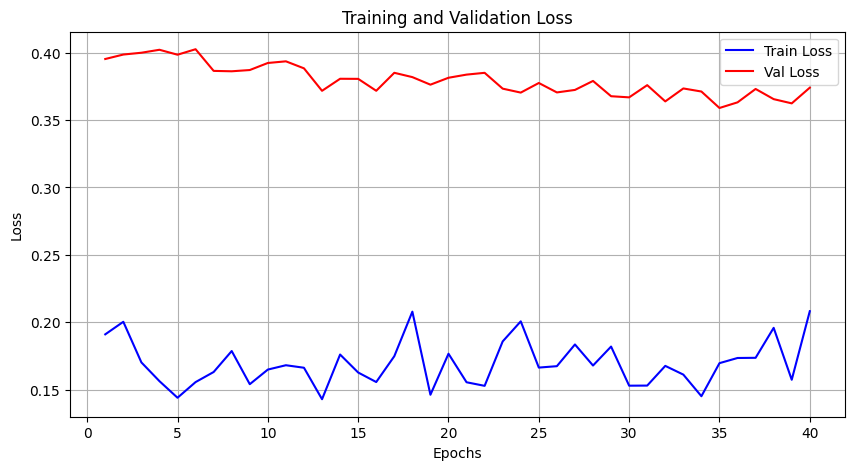

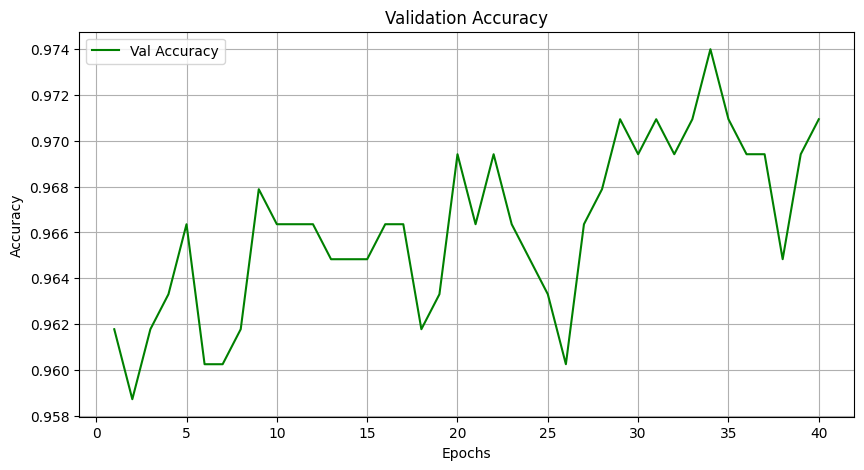

In [20]:
# 绘制损失曲线
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, epochs+1), val_losses, label='Val Loss', color='red')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# 绘制准确率曲线
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1), val_accs, label='Val Accuracy', color='green')
plt.title('Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

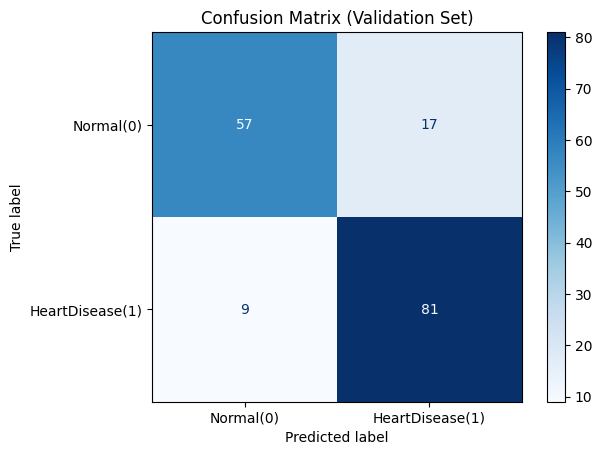

In [18]:
model.eval()
all_preds = []
all_targets = []
with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        preds = (torch.sigmoid(outputs) >= 0.5).float().cpu().numpy()
        #.cpu:数据存回cpu
        all_preds.extend(preds)
        all_targets.extend(y_batch.cpu().numpy())
        #用extend，它会自动把数组拆开，拍平成一个一维的大列表 ，这正是 confusion_matrix 需要的格式。

#绘制混淆矩阵
cm = confusion_matrix(all_targets, all_preds)#真实标签在前，预测结果在后
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal(0)', 'HeartDisease(1)'])
disp.plot(cmap=plt.cm.Blues)
#画热力图，颜色越深，数字越大
plt.title('Confusion Matrix (Validation Set)')
plt.show()

In [21]:
# 预测测试集
model.eval()
with torch.no_grad():
    X_test_tensor = X_test_tensor.to(device)
    test_outputs = model(X_test_tensor)
    # 将概率转为 0 或 1
    test_preds = (torch.sigmoid(test_outputs) >= 0.5).int().cpu().numpy().flatten()

# 组装提交文件
submission_df = pd.DataFrame({
    'id': test_ids,               # 这里使用我们从 test_df 提取出来的特定 id
    'HeartDisease': test_preds
})

# 保存为 CSV
submission_df.to_csv('my_submission.csv', index=False) 
# 为了避免覆盖原始 example_submission.csv，我先命名为 my_submission.csv

print("预测完成！前 5 行如下：")
print(submission_df.head())

预测完成！前 5 行如下：
    id  HeartDisease
0  669             0
1   31             1
2  378             1
3  536             1
4  808             0
